# LangChain Agent Memory: State vs Store


## Learning objectives

- Understand what State and Store each remember.
- See how State is scoped to a conversation `thread_id`.
- See how Store data can be accessed across different threads.
- Learn the key APIs: `runtime.state`, `Command(update=...)`, `runtime.store`, `store.put()` and `store.get()`.
- Run two independent demonstrations using an agent.

> Set `OPENAI_API_KEY` in your environment or a `.env` file before running the agent cells.

## 1. Fundamental difference

| Concept | State (short-term memory) | Store (long-term memory) |
|---|---|---|
| Scope | One conversation/thread | Can be shared across threads |
| Main purpose | Track conversation and current work | Save information for future conversations |
| Access in a tool | `runtime.state` | `runtime.store` |
| Write mechanism | `Command(update=...)` | `store.put(...)` |
| Read mechanism | Read state fields | `store.get(...)` |
| Persistence mechanism | Checkpointer | Store backend |
| Example | Current conversation messages | User preferences/profile |

**Mental model:** State remembers what is happening in this conversation. Store remembers information that may be useful in another conversation.

A `thread_id` identifies the conversation checkpoint. A Store namespace and key identify a stored item. A checkpointer and a Store solve different persistence problems.

## 2. Visualize the difference

Imagine Alice starts two separate conversations.

- Thread A has its own message history and state.
- Thread B has a different message history and state.
- Both threads can look up the same user record in a shared Store, provided they use the same namespace and key and the same Store backend.

```text
Conversation / Thread A  ----> State A (messages, task progress)
          | 
          +-------------------> Shared Store: ("users",) / "abc123"

Conversation / Thread B  ----> State B (its own messages, task progress)
          |
          +-------------------> Shared Store: ("users",) / "abc123"
```

Thread B does not automatically inherit Thread A's message history. It can still retrieve the user record from the shared Store.

# Part A — Short-term memory (State)

## 3. State fundamentals

State is the data associated with an agent conversation/thread. When a checkpointer is configured, LangGraph can save checkpoints and resume that thread on later invocations.

Inside a tool:
- Read current values using `runtime.state`.
- Return `Command(update={...})` when the tool needs to change state.

The following example stores a simple `task_status` field in addition to the built-in messages.

In [ ]:
from typing import Any

from typing_extensions import NotRequired

from langchain.agents import AgentState, create_agent
from langchain.tools import tool, ToolRuntime
from langchain.messages import ToolMessage
from langgraph.types import Command
from langgraph.checkpoint.memory import InMemorySaver
from langchain_openai import ChatOpenAI


In [ ]:
class TaskState(AgentState):
    task_status: NotRequired[str]


@tool
def update_task_status(
    status: str,
    runtime: ToolRuntime[None, TaskState],
) -> Command:
    """Update the current conversation's task status."""

    current_status = runtime.state.get("task_status", "not started")

    return Command(
        update={
            "task_status": status,
            "messages": [
                ToolMessage(
                    content=f"Task status changed from {current_status} to {status}.",
                    tool_call_id=runtime.tool_call_id,
                )
            ],
        }
    )


@tool
def get_task_status(runtime: ToolRuntime[None, TaskState]) -> str:
    """Read the current conversation's task status."""

    return runtime.state.get("task_status", "not started")

## 4. Create a State-enabled agent

`InMemorySaver` is a checkpointer for this learning example. Reusing the same `thread_id` resumes the same conversation state.

In [ ]:
state_checkpointer = InMemorySaver()

state_agent = create_agent(
    model=ChatOpenAI(model="gpt-5.5"),
    tools=[update_task_status, get_task_status],
    state_schema=TaskState,
    checkpointer=state_checkpointer,
    system_prompt=(
        "You manage task status for the current conversation. "
        "Use the tools to read or update the status."
    ),
)

thread_a_config = {
    "configurable": {
        "thread_id": "state-demo-thread-A"
    }
}

## 5. State — first invocation

The first call updates the state in Thread A.

In [ ]:
state_result_1 = state_agent.invoke(
    {
        "messages": [
            {"role": "user", "content": "Set my task status to in progress."}
        ]
    },
    config=thread_a_config,
)

print("Thread A task_status:", state_result_1.get("task_status"))

## 6. State — second invocation in the same thread

The same `thread_id` resumes Thread A. The tool can read the previously saved task status.

In [ ]:
state_result_2 = state_agent.invoke(
    {
        "messages": [
            {"role": "user", "content": "What is my task status now?"}
        ]
    },
    config=thread_a_config,
)

print("Thread A task_status:", state_result_2.get("task_status"))

## 7. State — a different thread

A new thread has its own state. It does not automatically inherit Thread A's task status.

In [ ]:
thread_b_config = {
    "configurable": {
        "thread_id": "state-demo-thread-B"
    }
}

state_result_thread_b = state_agent.invoke(
    {
        "messages": [
            {"role": "user", "content": "What is my task status?"}
        ]
    },
    config=thread_b_config,
)

print("Thread B task_status:", state_result_thread_b.get("task_status", "not started"))

# Part B — Long-term memory (Store)

## 8. Store fundamentals

A Store holds data that can be retrieved independently of a particular conversation thread.

A stored item is organized using:
- **Namespace:** a tuple grouping related records, such as `("users",)`.
- **Key:** the unique identifier within that namespace, such as `"abc123"`.
- **Value:** the data being stored, such as a user's name, age, and email.

Example:

```python
store.put(
    ("users",),
    "abc123",
    {"name": "Foo", "age": 25, "email": "foo@example.com"}
)

item = store.get(("users",), "abc123")
```

`item.value` contains the stored value when the item exists. `InMemoryStore` is useful for learning; use a persistent store backend for production.
![Screenshot From 2026-11-08 15-58-46.png](<attachment:Screenshot From 2026-11-08 15-58-46.png>)
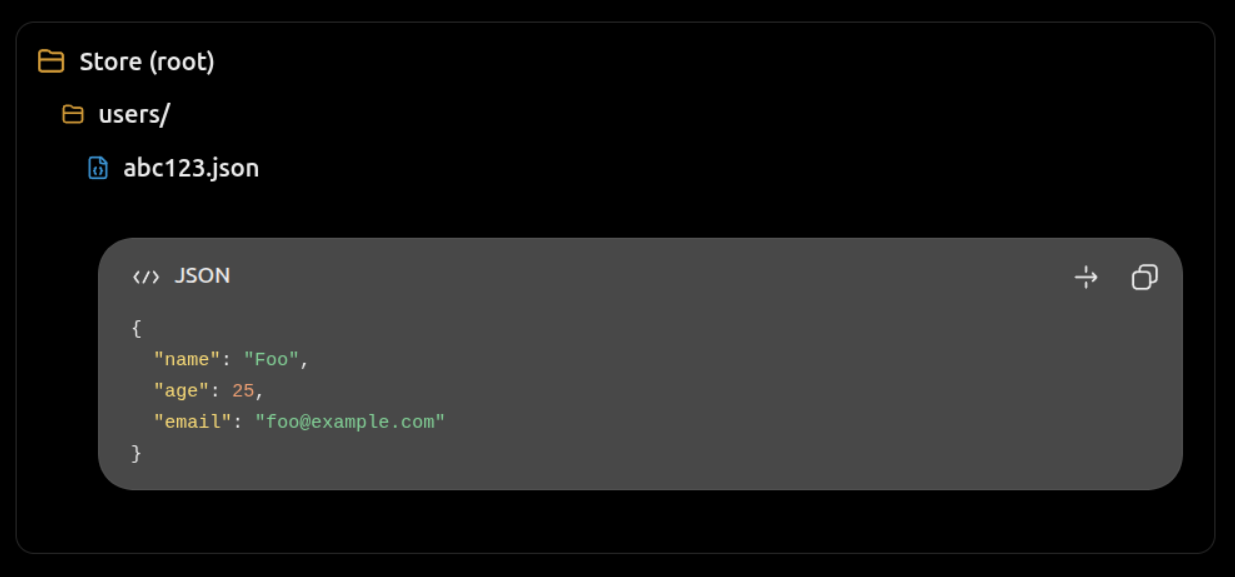

In [ ]:
from langgraph.store.memory import InMemoryStore

# One shared store instance used by the Store demonstration
long_term_store = InMemoryStore()

## 9. Create Store tools

`runtime.store` gives the tool access to the Store configured on the agent.

- `store.put(namespace, key, value)` writes or replaces the item at that namespace/key.
- `store.get(namespace, key)` retrieves the item, or returns `None` if it does not exist.

The namespace is a tuple, even when it contains just one string.

In [ ]:
@tool
def save_user_info(
    user_id: str,
    name: str,
    age: int,
    email: str,
    runtime: ToolRuntime,
) -> str:
    """Save a user's information in long-term memory."""

    store = runtime.store

    store.put(
        ("users",),
        user_id,
        {
            "name": name,
            "age": age,
            "email": email,
        },
    )

    return "Successfully saved user information."


@tool
def get_user_info(
    user_id: str,
    runtime: ToolRuntime,
) -> str:
    """Retrieve a user's information from long-term memory."""

    store = runtime.store
    user_info = store.get(("users",), user_id)

    if user_info is None:
        return "Unknown user."

    return str(user_info.value)

## 10. Create a Store-enabled agent

Notice that this agent receives `store=long_term_store`. Unlike the State example, this example does not require a checkpointer to demonstrate cross-thread Store access.

In [ ]:
store_agent = create_agent(
    model=ChatOpenAI(model="gpt-5.5"),
    tools=[save_user_info, get_user_info],
    store=long_term_store,
    system_prompt=(
        "You manage user information. Use save_user_info to save records "
        "and get_user_info to retrieve them. Do not invent user details."
    ),
)

## 11. Store — save information in one session

The agent writes the user record into the shared Store.

In [ ]:
save_result = store_agent.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": (
                    "Save this user: user_id abc123, name Foo, age 25, "
                    "email foo@example.com."
                ),
            }
        ]
    }
)

print(save_result["messages"][-1].content)

## 12. Store — retrieve information from another session

Invoke the same Store-enabled agent again. There is no `thread_id` shared with the previous call here; the record is retrieved using the same Store namespace and key.

In [ ]:
get_result = store_agent.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": "Get the user information for user ID abc123."
            }
        ]
    }
)

print(get_result["messages"][-1].content)

## 13. Inspect the Store directly

This cell bypasses the LLM and shows the underlying Store item. It makes the namespace/key/value structure explicit.

In [ ]:
stored_item = long_term_store.get(("users",), "abc123")

if stored_item is not None:
    print("Namespace:", stored_item.namespace)
    print("Key:", stored_item.key)
    print("Value:", stored_item.value)
else:
    print("No item found.")

## 14. Final comparison

| Question | State | Store |
|---|---|---|
| What does it represent? | Current conversation data | Data shared across conversations |
| How is it identified? | `thread_id` | Namespace + key |
| How does a tool read it? | `runtime.state` | `runtime.store` |
| How does a tool write it? | `Command(update=...)` | `store.put(...)` |
| What enables persistence? | Checkpointer | Store implementation |
| Example | Current task status | User profile |

### Remember

**State = memory of this conversation.**

**Store = information available beyond this conversation.**

A Store is not automatically injected into the model's prompt. Your agent/tool must retrieve relevant information and return it or otherwise use it.

`InMemoryStore` and `InMemorySaver` are in-memory learning implementations. Their contents are not durable across process restarts. For production, choose persistent backends and apply appropriate authentication, authorization, and data-retention controls.

### Official documentation

- [LangChain Tools — Access context / Store](https://docs.langchain.com/oss/python/langchain/tools#access-context)
- [LangGraph — Add memory](https://docs.langchain.com/oss/python/langgraph/add-memory)
- [BaseStore reference](https://reference.langchain.com/python/langchain-core/stores/BaseStore)